# CarFair-TN : nettoyage et préparation des données

**Objectif du projet** : estimer le juste prix d'une voiture d'occasion en Tunisie à partir de ses caractéristiques
(marque, modèle, année, kilométrage, motorisation…). Le modèle est entraîné sur des annonces publiées sur
**[tayara.tn](https://www.tayara.tn)**, principal site de petites annonces du pays, puis servi dans une application Streamlit.

**Rôle de ce notebook** : transformer les annonces brutes collectées par scraping en un jeu de données fiable pour
l'entraînement. C'est l'étape la plus déterminante du projet : sur une marketplace, les vendeurs remplissent les
champs librement, et une grande partie des valeurs est fausse, incomplète ou volontairement fantaisiste.

### Anomalies mises en évidence lors de l'exploration

L'exploration des données brutes (`01_eda.ipynb`) a mis en évidence les problèmes suivants, que ce notebook corrige :

| Problème | Exemple réel |
|---|---|
| Prix « à discuter par téléphone » remplacés par des valeurs factices | `5`, `1234`, `55 111 110` (131 annonces) |
| Prix saisis en milliers de dinars | Polo 2020 à `61` (= 61 000 TND) |
| Prix saisis en millimes (1 TND = 1000 millimes) | Kia Rio 2017 à `36 000 000` |
| Numéros de téléphone dans le champ prix | `29 703 514`, `91 241 453` |
| Kilométrages saisis en milliers | BMW 2014 à « 170 km » |
| Kilométrage et année collés par le scraping | `1440002021` = 144 000 km + 2021 |
| Valeurs numériques absurdes | puissance fiscale de 1.1e15, année `9999` |
| Marques par défaut, texte dans les champs marque et modèle | « AC Cobra » pour une Tesla Model Y, modèle « Afficher le numéro » |
| Annonces qui ne sont pas des voitures | pneus, rétroviseurs, location avec chauffeur |
| Annonces publiées plusieurs fois | ~300 reposts |

### Approche

Deux principes guident tout le notebook :

1. **Corriger plutôt que supprimer quand la correction est sûre.** Un prix de `61` pour une Polo 2020 n'est pas une
   donnée inutilisable : c'est 61 000 TND. Chaque correction automatique est ensuite vérifiée par un contrôle de
   plausibilité, et tracée dans une colonne d'audit.
2. **Ne faire ici que des corrections ligne par ligne.** Chaque annonce est corrigée à partir de ses propres champs
   (et de son titre / sa description). Les imputations qui s'appuient sur des statistiques calculées sur d'autres
   annonces (médianes, valeurs les plus fréquentes) sont **volontairement reportées** dans le pipeline de modélisation,
   où elles seront apprises sur le jeu d'entraînement uniquement. Les faire ici laisserait fuiter de l'information du
   jeu de test vers l'entraînement et rendrait l'évaluation trop optimiste.

Les règles de nettoyage sont codées dans `src/cleaning.py` (fonctions réutilisables et testables, partagées avec
l'application) ; ce notebook les applique, montre leur effet et justifie chaque décision.

### Plan

1. Chargement des données brutes
2. Suppression des doublons
3. Préparation du texte des annonces
4. Harmonisation des catégories
5. Contrôle des plages numériques
6. Récupération des valeurs manquantes depuis le texte
7. Correction du kilométrage
8. Règle métier sur la boîte de vitesses
9. Exclusion des annonces hors sujet
10. Reconstruction du prix (variable cible)
11. Dataset final et export
12. Imputation dans le pipeline de modélisation
13. Bilan et limites

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

from src import cleaning as cl

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

# Couleurs : série principale, encre et grille discrètes
C1 = "#2a78d6"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12,
})

funnel = []  # (étape, nb de lignes) pour le bilan final
def log_step(name):
    funnel.append((name, len(df)))
    print(f"{name:<35} {len(df):>6,} lignes")

## 1. Chargement des données brutes

7 178 annonces collectées par scraping (fin 2025), 17 colonnes : les champs structurés du site (prix, kilométrage,
année, marque, modèle, cylindrée, puissance fiscale, boîte, carburant, carrosserie, couleur, état), le titre et la
description libres, un identifiant d'annonce, la ville et la date de publication (données anonymisées : voir
`01_eda.ipynb`).

Le taux de valeurs manquantes donne une première idée de la qualité : près d'une annonce sur quatre n'a pas de prix.

In [2]:
df = pd.read_csv(RAW_DIR / "tayara_cars_all_pages.csv")
log_step("Données brutes")
df.isna().mean().mul(100).round(1).sort_values(ascending=False).to_frame("% manquant").T

Données brutes                       7,178 lignes


,posting_time,location,prix,description,type_de_carrosserie,puissance_fiscale,cylindree,modele,etat_du_vehicule,annee,kilometrage,carburant,marque,boite,couleur_du_vehicule,titre,id_annonce
% manquant,56.9,56.9,22.8,21.0,15.0,14.3,13.2,10.3,9.9,9.0,8.9,6.2,5.8,5.5,5.3,0.0,0.0


## 2. Suppression des doublons

Deux niveaux :

- **même identifiant d'annonce** : la même annonce collectée deux fois par le scraper ;
- **même titre, description et prix** : un vendeur qui republie son annonce pour la faire remonter dans les résultats.

Les doublons ne sont pas qu'un problème de volume : lors du découpage aléatoire entre entraînement et test, deux copies
de la même voiture peuvent se retrouver de part et d'autre. Le modèle est alors évalué sur des voitures qu'il a déjà
vues, et ses performances paraissent meilleures qu'elles ne le sont.

In [3]:
df = df.drop_duplicates("id_annonce")
log_step("Dédoublonnage par identifiant")
df = df.drop_duplicates(["titre", "description", "prix"])
log_step("Dédoublonnage des reposts")
df = df.reset_index(drop=True)

Dédoublonnage par identifiant        7,129 lignes
Dédoublonnage des reposts            6,842 lignes


## 3. Préparation du texte des annonces

Le titre et la description contiennent souvent l'information absente des champs structurés (« Golf 7 TDI 2016,
120 000 km, prix 45 000 dt »). On construit pour chaque annonce un texte unique, en minuscules et sans accents, qui
servira aux extractions des étapes suivantes.

Le scraping ajoute « Lire plus » à la fin de chaque description. On le supprime : sans cela, une règle qui cherche une
cylindrée (« 1.6 **l** ») lirait « 2023 **L**ire plus » comme un moteur de 2.023 litres.

In [4]:
print("Descriptions contenant 'Lire plus' :", df["description"].fillna("").str.contains("Lire plus").sum())
df["texte"] = df.apply(cl.listing_text, axis=1)
df["texte"].head(3).tolist()

Descriptions contenant 'Lire plus' : 5514


['suzuki celerio, premiere main . suzuki celerio a vendre premiere main, faible kilometrage (53600km), entretien maison suzuki,',
 'toyota corolla dynamic – 2021 – 49 900 km – excellent etat . je vends ma toyota corolla hatchback – finition dynamic – annee 2021, tres bien equipee, fiable et economique. vehicule entretenu chez toyota la marsa, non fumeur, aucun frais a prevoir. 🔧 mecanique & performances moteur essence 1.2l – 116 ch boite automatique cvt consommation mixte : 5,5 l / 100 km modes de conduite : eco / normal / sport kilometrage : 49 900 km vitesse max : 200 km/h 0–100 km/h : 10,3 s 🛡 securite & conduite 7 airbags abs + ba + ebd trc + vsc aide au demarrage en cote (hac) frein de stationnement electrique camera de recul avec trajectoire allumage automatique des phares essuie-glaces automatiques 🎛 technologie & confort acces et demarrage sans cle : smart entry / smart start ecran tactile toyota touch 8" bluetooth / usb / aux climatisation automatique bizone ordinateur de bord

## 4. Harmonisation des catégories

Une même catégorie apparaît sous plusieurs écritures (`Essence` / `essence`, `Compact` / `Compacte`, `Or` / `Doré`).
Pour un modèle, ce sont des catégories différentes : on unifie tout en minuscules, sans accents, et on fusionne les
synonymes.

**Marque : liste de référence.** La marque est validée par une liste fermée, écrite dans `src/cleaning.py` et
indépendante des données : les marques présentes sur le site, complétées par les marques vendues ou importées en Tunisie,
avec leurs variantes d'écriture (« Mercedes » → `mercedes-benz`, « VW » → `volkswagen`). Une liste construite à partir du
dataset ne conviendrait pas : elle contiendrait les erreurs qu'on cherche justement à détecter.

Sont rejetés : le texte de description tombé dans le champ (« Lire plus », « Pré-installation pour DISTRONIC ») et les
marques **AC** et **Acrea**. Premières de la liste alphabétique du site, elles servent de valeur par défaut : les
annonces « AC » sont une Tesla Model Y, une moto, un fonds de commerce… Quand la marque saisie est rejetée, le modèle
l'est aussi, puisqu'il a été choisi dans la liste de cette fausse marque (« AC Cobra » pour la Tesla). La marque pourra
être retrouvée dans le titre à l'étape 6.

Le site range aussi une partie des Range Rover sous la marque « Rover » (la même coupure que `over.Range Rover`) :
un Range Rover étant toujours un Land Rover, la marque est corrigée à partir du modèle.

**Modèle : filtre de forme.** Le préfixe de marque ajouté par le site est retiré (`Peugeot.208` → `208`,
`over.Range Rover Evoque` → `range rover evoque`), et le texte de description est rejeté (« Afficher le numéro »,
« • SUV robuste et confortable… ») : caractères de mise en forme, mots comme « afficher » ou « prix », plus de 4 mots.

**Autres champs : vocabulaire fermé.** Une valeur qui n'en fait pas partie, comme « 📞 Contact : » dans le champ
carburant (du texte de description tombé dans le mauvais champ), devient une valeur manquante plutôt qu'une catégorie
parasite.

In [5]:
before = df["carburant"].value_counts(dropna=False)

raw_marque, raw_modele = df["marque"], df["modele"]
df["marque"] = raw_marque.map(cl.normalize_marque)
df["modele"] = raw_modele.map(cl.normalize_modele)

# Marque saisie absente de la liste de référence : le modèle, choisi dans la liste de cette marque, est faux aussi
invalid_brand = raw_marque.notna() & df["marque"].isna()
df.loc[invalid_brand, "modele"] = np.nan
print("Marques rejetées :", raw_marque[invalid_brand].value_counts().to_dict())
print("Modèles rejetés (texte) :", raw_modele[raw_modele.notna() & df["modele"].isna() & ~invalid_brand].value_counts().to_dict())

range_rover = df["modele"].str.startswith("range rover", na=False) & (df["marque"] != "land rover")
df["marque"] = [cl.fix_marque_from_modele(m, mo) for m, mo in zip(df["marque"], df["modele"])]
print("Range Rover rangés sous une autre marque → land rover :", int(range_rover.sum()))

prefixed = raw_modele.notna() & raw_modele.str.contains(r"^[A-Za-z][A-Za-z -]*\.", regex=True)
display(pd.DataFrame({"modèle saisi": raw_modele[prefixed], "modèle retenu": df.loc[prefixed, "modele"]}).drop_duplicates().head(8))

df["carburant"] = df["carburant"].map(lambda v: cl.normalize_category(v, cl.CARBURANT_MAP))
df["boite"] = df["boite"].map(lambda v: cl.normalize_category(v, cl.BOITE_MAP))
df["type_de_carrosserie"] = df["type_de_carrosserie"].map(lambda v: cl.normalize_category(v, cl.CARROSSERIE_MAP))
df["etat_du_vehicule"] = df["etat_du_vehicule"].map(lambda v: cl.normalize_category(v, cl.ETAT_MAP))
df["couleur_du_vehicule"] = df["couleur_du_vehicule"].map(cl.normalize_couleur)

display(before.rename("avant").to_frame())
display(df["carburant"].value_counts(dropna=False).rename("après").to_frame())

Marques rejetées : {'AC': 22, 'Lire plus': 1, 'Pré-installation pour DISTRONIC': 1, 'Acrea': 1}
Modèles rejetés (texte) : {'Afficher le numéro': 3, '🔸 Clim, direction assistée, vitres électriques': 1, 'FEUX : LED': 1, '• SUV robuste et confortable, idéal pour la ville comme pour les longs trajets': 1}
Range Rover rangés sous une autre marque → land rover : 15


,modèle saisi,modèle retenu
395,over.Range Rover Evoque,range rover evoque
396,over.Range Rover,range rover
649,Fiat.Punto,punto
666,Mercedes-Benz.Classe E,classe e
965,over.Range Rover Sport,range rover sport
1251,Peugeot.208,208
1463,Peugeot.206,206
1513,Fiat.Doblo,doblo


,avant
carburant,
Essence,4253
Diesel,2016
NaN,342
Hybride essence,156
Hybride Diesel,33
Electrique,25
Hybride,12
✔️ Idéale pour la ville,1
Faible kilométrage certifié.,1


,après
carburant,
essence,4253
diesel,2016
NaN,347
hybride essence,168
hybride diesel,33
electrique,25


## 5. Contrôle des plages numériques

Une valeur hors de toute plage réaliste est une erreur de saisie, pas un cas extrême à conserver :

- `annee` doit être entre 1980 et 2026 (on trouve `0` et `9999`) ;
- `puissance_fiscale` doit être entre 1 et 30 CV (on trouve `0` et 1.1e15) ;
- `cylindree` est convertie en litres (`1.6L`, `1461 cm3`, `<1.0L`) et doit être entre 0.6 et 7 L.

Les valeurs invalides deviennent manquantes. On ne les remplace pas ici par une médiane : ce serait une imputation
apprise sur l'ensemble des données (voir l'approche en introduction).

In [6]:
raw_numeric = df[["annee", "puissance_fiscale"]].describe().loc[["min", "max"]]

df["annee"] = df["annee"].map(cl.clean_annee)
df["puissance_fiscale"] = df["puissance_fiscale"].map(cl.clean_puissance_fiscale)
df["cylindree"] = df["cylindree"].map(cl.parse_cylindree)

print("Avant :"); display(raw_numeric)
print("Après :"); display(df[["annee", "puissance_fiscale", "cylindree"]].describe().loc[["min", "max"]])

Avant :


,annee,puissance_fiscale
min,0.0,0.000000e+00
max,9999.0,1.111111e+15


Après :


,annee,puissance_fiscale,cylindree
min,1980.0,1.0,0.8
max,2026.0,30.0,5.0


## 6. Récupération des valeurs manquantes depuis le texte

Quand un champ est vide, l'information se trouve souvent dans le titre ou la description de la même annonce. On la
recherche avec des règles (expressions régulières) conçues pour éviter les faux positifs :

- **marques** recherchées dans la liste de référence de l'étape 4, **d'abord dans le titre, puis dans la description**.
  Certains noms sont ambigus : dans un titre, « mini » ou « jeep » désignent presque toujours la marque, mais dans une
  description on lit « prix mini » ou « jeep » pour un 4x4. Ils ne sont donc cherchés que dans le titre. « Smart »,
  qui est aussi une finition (« Polo 8 Smart »), n'est accepté qu'avec un modèle (« smart fortwo ») ;
- **mots entiers uniquement** : chercher `or` (la couleur) comme simple suite de lettres le trouverait dans
  « m**o**teu**r** » et `van` dans « a**van**t » ;
- **codes moteur** exploités pour le carburant : `tdi`, `hdi`, `dci` → diesel ; `tsi`, `vti`, `puretech` → essence ;
- **puissance fiscale** lue uniquement via « cv » (en Tunisie, « ch » / « chevaux » désigne la puissance réelle, une
  autre grandeur) ;
- **règles prudentes pour l'état** : « comme neuf » est une formule courante pour des voitures d'occasion et ne
  permet pas de conclure à un véhicule neuf ; « RS » n'est pas lu dans le texte car il désigne aussi des versions
  sportives (Audi RS3, Clio RS).

Le tableau indique, pour chaque colonne, combien de valeurs manquantes ont pu être récupérées.

In [7]:
extraction = []

def fill_from_text(col, extract):
    missing = df[col].isna()
    values = df.loc[missing, "texte"].map(extract)
    df.loc[missing, col] = values
    extraction.append({"colonne": col, "manquants": int(missing.sum()), "récupérés": int(values.notna().sum())})

# Marque : d'abord dans le titre, puis dans la description (liste de référence, pas les valeurs du dataset)
title_patterns = cl.build_brand_patterns("titre")
text_patterns = cl.build_brand_patterns("description")
missing = df["marque"].isna()
from_title = df.loc[missing, "titre"].map(lambda t: cl.extract_marque(cl.normalize_text(t), title_patterns))
from_text = df.loc[missing, "texte"].map(lambda t: cl.extract_marque(t, text_patterns))
values = from_title.fillna(from_text)
df.loc[missing, "marque"] = values
extraction.append({"colonne": "marque", "manquants": int(missing.sum()), "récupérés": int(values.notna().sum())})

brand_models = df.dropna(subset=["marque", "modele"]).groupby("marque")["modele"].unique().to_dict()
model_patterns = cl.build_model_patterns(brand_models)
missing = df["modele"].isna() & df["marque"].notna()
values = df[missing].apply(lambda r: cl.extract_modele(r["texte"], r["marque"], model_patterns), axis=1)
df.loc[missing, "modele"] = values
extraction.append({"colonne": "modele", "manquants": int(missing.sum()), "récupérés": int(values.notna().sum())})

for col, fn in [
    ("annee", cl.extract_annee),
    ("puissance_fiscale", cl.extract_puissance_fiscale),
    ("cylindree", cl.extract_cylindree),
    ("carburant", cl.extract_carburant),
    ("boite", cl.extract_boite),
    ("couleur_du_vehicule", cl.extract_couleur),
    ("etat_du_vehicule", cl.extract_etat),
    ("type_de_carrosserie", cl.extract_carrosserie),
]:
    fill_from_text(col, fn)

pd.DataFrame(extraction).assign(taux=lambda d: (d["récupérés"] / d["manquants"] * 100).round(1))

,colonne,manquants,récupérés,taux
0,marque,343,167,48.7
1,modele,486,212,43.6
2,annee,590,110,18.6
3,puissance_fiscale,1180,92,7.8
4,cylindree,835,26,3.1
5,carburant,347,43,12.4
6,boite,299,24,8.0
7,couleur_du_vehicule,283,10,3.5
8,etat_du_vehicule,610,60,9.8
9,type_de_carrosserie,955,39,4.1


> Pour retrouver un modèle dans le texte, on utilise la liste des modèles connus de chaque marque, tirée du dataset.
> C'est un **vocabulaire** (quels noms existent), pas une statistique calculée sur les prix ou les autres features :
> il ne crée pas de fuite entre entraînement et test.

## 7. Correction du kilométrage

Trois défauts distincts :

1. **Année collée au kilométrage** lors du scraping : `1440002021` correspond à 144 000 km et à l'année 2021. Quand les
   derniers chiffres reproduisent l'année de l'annonce, on les retire.
2. **Kilométrage saisi en milliers** : « 181 » signifie 181 000 km. L'état déclaré n'est pas fiable pour trancher
   (dans l'EDA, 464 annonces « Nouveau » affichent entre 1 et 999 km, dont une BMW de 2014 à « 170 km »). La règle repose donc sur
   **l'âge du véhicule** : une valeur inférieure à 1 000 sur une voiture de plus d'un an est multipliée par 1 000, à
   condition que le résultat reste réaliste (moins de 60 000 km par an). Sinon la valeur est jugée ambiguë et laissée
   manquante.
3. **Valeurs factices** : `1111111`, un numéro de téléphone, ou `0 km` sur une voiture de dix ans deviennent manquants.

Le tableau montre combien de lignes sont concernées par chaque règle, suivi d'exemples. Les kilométrages encore
manquants seront imputés dans le pipeline de modélisation (médiane par année et état, apprise sur l'entraînement).

In [8]:
km_raw = df["kilometrage"].copy()
missing = km_raw.isna()
km_raw[missing] = df.loc[missing, "texte"].map(cl.extract_kilometrage)
print("Kilométrages récupérés depuis le texte :", int(km_raw[missing].notna().sum()))

fixed = [cl.fix_kilometrage(k, a) for k, a in zip(km_raw, df["annee"])]
df["kilometrage"] = [v for v, _ in fixed]
km_tag = pd.Series([t for _, t in fixed], index=df.index)

display(km_tag.value_counts().rename("lignes").to_frame())
examples = pd.DataFrame({"brut": km_raw, "annee": df["annee"], "corrigé": df["kilometrage"], "règle": km_tag})
examples[examples["règle"].isin(["x1000", "glued_year", "placeholder"])].groupby("règle").head(4)

Kilométrages récupérés depuis le texte : 48


,lignes
original,4604
x1000,1418
missing,481
placeholder,234
ambiguous,97
glued_year,8


,brut,annee,corrigé,règle
2,170,2014.0,170000.0,x1000
3,170,2014.0,170000.0,x1000
4,2202021,2021.0,220000.0,x1000
11,182,2016.0,182000.0,x1000
31,0,2020.0,NaN,placeholder
88,95763496,2020.0,NaN,placeholder
209,0,1997.0,NaN,placeholder
217,0000,2013.0,NaN,placeholder
1966,1440002021,2021.0,144000.0,glued_year
2089,1900002009,2009.0,190000.0,glued_year


## 8. Règle métier sur la boîte de vitesses

Certaines informations relèvent de la connaissance automobile plutôt que des données : une Audi A8 postérieure à 2002
n'existe qu'en boîte automatique. Ce type de règle écrite à la main ne dépend d'aucune autre annonce et peut donc être
appliqué ici.

L'imputation générale de la boîte (boîte la plus fréquente pour la même marque, le même modèle et la même année) est,
elle, apprise sur les données : elle est réalisée dans le pipeline de modélisation.

In [9]:
a8 = (df["marque"] == "audi") & (df["modele"] == "a8") & (df["annee"] >= 2003) & df["boite"].isna()
df.loc[a8, "boite"] = "automatique"
print("Audi A8 ≥ 2003 → automatique :", int(a8.sum()))

Audi A8 ≥ 2003 → automatique : 0


## 9. Exclusion des annonces hors sujet

La catégorie « voitures » du site contient aussi des pièces détachées, des pneus, des offres de location et des
annonces de recherche (« je cherche une C3 diesel »). Elles n'ont pas leur place dans un modèle de prix de véhicules.

Les règles sont volontairement strictes pour ne pas exclure de vraies voitures : le titre doit **commencer** par une
pièce (« Rétroviseur pajero 3 ») ou contenir une expression sans ambiguïté (« pour pièces », « location »).
« Golf 7 jantes alu » ou « Mercedes C180 kit AMG » restent des voitures.

Ce filtre doit passer **avant** la reconstruction des prix : sans lui, une annonce « Location voiture » affichée à 90 TND serait interprétée
comme une voiture à 90 000 TND par la règle des prix saisis en milliers.

On exige ensuite une **marque** et une **année** : ce sont les deux informations sans lesquelles aucune estimation de
prix n'a de sens.

In [10]:
non_car = df["titre"].map(cl.is_non_car)
display(df.loc[non_car, ["titre", "prix"]].head(12))
df = df[~non_car]
log_step("Suppression des non-voitures")

df = df.dropna(subset=["marque", "annee"])
log_step("Marque et année obligatoires")

,titre,prix
199,opel omega b break pour piece seulement,21.0
217,Divers Pièces et accessoires pour PEUGEOT 508 .,NaN
218,Pièces et accessoires divers pour Peugeot 3008 .Tel:59 2...,NaN
293,4 Roues (Jante Alu + Pneu PIRELLI) VW 215/60/R16,NaN
488,"🚨4 roues range rover sport par 20""",3300.0
506,"🚨4 roues range rover sport par 20""",3300.0
1022,pieces punto 2,499.0
1382,Pièces d'occasions pour GRAND I10,11.0
1408,je cherche location de voiture commercial,1500.0
1574,accessoire Haval H6,NaN


Suppression des non-voitures         6,775 lignes
Marque et année obligatoires         6,260 lignes


## 10. Reconstruction du prix (variable cible)

Le prix est ce que le modèle apprend à prédire : chaque erreur dans cette colonne est une erreur enseignée au modèle.
Plutôt que de supprimer toutes les valeurs hors d'une fourchette fixe, ce qui éliminerait aussi les ~800 annonces dont
le prix est simplement saisi en milliers, on interprète chaque valeur.

### 10.1 Interprétation de la valeur saisie

| Valeur saisie | Interprétation | Action |
|---|---|---|
| 1 – 9 | valeur factice (`5` apparaît 72 fois) | supprimée |
| `123`, `1234`, `999999`, `55111110`, chiffres répétés | « prix à discuter » | supprimée |
| 10 – 999 | prix en milliers (Polo 2020 à `61`) | ×1000 |
| 8 chiffres commençant par 2, 4, 5 ou 9, non arrondi | numéro de téléphone tunisien | supprimée |
| plus de 1 000 000 et multiple de 1000 | prix en millimes | ÷1000 |
| 1 000 – 1 000 000 | prix en dinars | conservée |

La colonne `prix_correction` garde la trace de la règle appliquée à chaque annonce.

In [11]:
normalized = [cl.normalize_price(p) for p in df["prix"]]
df["prix_candidat"] = [v for v, _ in normalized]
df["prix_correction"] = [t for _, t in normalized]
df["prix_correction"].value_counts().rename("lignes").to_frame()

,lignes
prix_correction,
original,3533
missing,1329
x1000,860
placeholder,458
millimes,40
phone,36
garbage,4


### 10.2 Contrôle de plausibilité

Une règle automatique peut se tromper : « 500 » est-il un 4x4 à 500 000 TND ou une pièce à 500 TND ? Chaque prix est
donc comparé à un **prix de référence** : la médiane des annonces jugées fiables (prix saisi directement entre 5 000 et
1 000 000 TND) pour des voitures similaires. On cherche d'abord la même marque, le même modèle et la même année, puis
on élargit progressivement (marque + année, marque + modèle, marque, année) jusqu'à trouver au moins 3 annonces.

- un prix **corrigé** (×1000, millimes, texte) est accepté s'il est à moins d'un facteur **3** de la référence ;
- un prix **saisi tel quel** est accepté jusqu'à un facteur **4** : on n'écarte que les erreurs grossières, comme
  4 900 TND pour une Renault Symbol de 2019 (référence : 45 100 TND).

Si le prix saisi est absent ou rejeté, on cherche un prix **explicitement annoncé** dans le texte (« prix : 38 000 »,
« 46MD », « 95000 dinars »). Les mentions de prix neuf (« vendue chez BMW Tunisie à partir de 440 000 dt ») sont
ignorées, car elles ne reflètent pas le prix de l'occasion.

> **Pourquoi ce contrôle ne crée pas de fuite.** Il s'appuie sur d'autres annonces, mais il sert uniquement à écarter
> des prix faux. La référence n'est jamais donnée au modèle comme variable : c'est un contrôle qualité de la cible,
> appliqué de la même façon à toutes les annonces.
>
> **Limite.** Si les annonces de référence d'un groupe sont elles-mêmes erronées, une annonce correcte peut être
> rejetée. Les exemples de rejets affichés ci-dessous permettent de vérifier que ces cas restent minoritaires.

In [12]:
trusted = (df["prix_correction"] == "original") & df["prix_candidat"].between(5_000, 1_000_000)
ref_log = cl.price_plausibility_reference(df, trusted)

def is_plausible(price, tolerance):
    return (np.log(price) - ref_log).abs() <= np.log(tolerance)

tolerance = np.where(df["prix_correction"] == "original", 4, 3)
ok_field = is_plausible(df["prix_candidat"], tolerance).fillna(False)
display(pd.crosstab(df["prix_correction"], ok_field.map({True: "accepté", False: "rejeté"})))

# Repli sur le prix annoncé dans le texte
need = ~ok_field
text_price = df.loc[need, "texte"].map(cl.extract_prix).map(lambda v: cl.normalize_price(v)[0])
ok_text = is_plausible(text_price, 3).reindex(text_price.index).fillna(False)
print(f"Prix trouvés dans le texte : {text_price.notna().sum()}  |  acceptés : {ok_text.sum()}")

df["prix"] = df["prix_candidat"].where(ok_field)
df.loc[ok_text[ok_text].index, "prix"] = text_price[ok_text]
df.loc[ok_text[ok_text].index, "prix_correction"] = "texte"

rejected = df[df["prix"].isna() & df["prix_candidat"].notna()]
print("\nExemples de prix rejetés par le contrôle de plausibilité :")
display(rejected.assign(reference=np.exp(ref_log[rejected.index]).round(-2))
        [["titre", "prix_candidat", "prix_correction", "reference", "marque", "modele", "annee"]].head(10))

df = df.dropna(subset=["prix"])
log_step("Prix valide (cible)")
df["prix_correction"].value_counts().rename("lignes").to_frame()

col_0,accepté,rejeté
prix_correction,,
garbage,0,4
millimes,35,5
missing,0,1329
original,3449,84
phone,0,36
placeholder,0,458
x1000,787,73


Prix trouvés dans le texte : 55  |  acceptés : 38



Exemples de prix rejetés par le contrôle de plausibilité :


,titre,prix_candidat,prix_correction,reference,marque,modele,annee
69,Renault Mégane,1200.0,millimes,24500.0,renault,megane,1999.0
105,IVECO daily 35 C15 Neuf,11000.0,x1000,70000.0,iveco,daily,2024.0
173,CLIO 4 limited Fin serie moteur symbole,1212.0,original,49500.0,renault,clio,2018.0
207,Super 5 tel 27640729,5000.0,original,27500.0,renault,super 5,1991.0
209,Mercedes benz,12000.0,original,79000.0,mercedes-benz,NaN,1997.0
212,A vendre,15000.0,original,73000.0,bmw,serie 5,1995.0
233,Symbole série 3,4900.0,original,45100.0,renault,symbol,2019.0
242,OPEL ISUZU 4 PORTES 4X4,1999.0,original,56500.0,isuzu,landwind,1996.0
380,🇩🇪 BYD SEALION 7 🇨🇳,189000.0,x1000,61400.0,byd,f3,2025.0
383,BMW IX 40,228000.0,x1000,63000.0,bmw,x4,2023.0


Prix valide (cible)                  4,309 lignes


,lignes
prix_correction,
original,3449
x1000,787
texte,38
millimes,35


In [13]:
print("Exemples de prix récupérés par ×1000 :")
df[df["prix_correction"] == "x1000"][["titre", "prix", "annee", "marque", "modele"]].sample(8, random_state=3)

Exemples de prix récupérés par ×1000 :


,titre,prix,annee,marque,modele
1135,Honda CR-V,145000.0,2022.0,honda,cr-v
3365,Ford focus trend sport,42000.0,2015.0,ford,focus
6198,amarok model 2013,50000.0,2013.0,volkswagen,amarok
2749,À vendre Citroën K9,50000.0,2020.0,citroen,berlingo
5279,kia cerato,44000.0,2015.0,kia,cerato
1182,Peugeot 208 Diesel,39000.0,2019.0,peugeot,208
3848,voiture,58000.0,2017.0,mazda,bt-50
4699,Renault express,10000.0,1995.0,renault,express


## 11. Dataset final et export

- **Dernière déduplication** : même voiture et même prix sous un identifiant différent (annonce republiée avec un texte
  légèrement modifié).
- **`prix` et `prix_log`** sont exportés côte à côte. Les prix sont très asymétriques (beaucoup de citadines, quelques
  voitures de luxe) : le modèle apprendra sur `prix_log = log(1 + prix)`, et le prix en dinars reste lisible dans le
  fichier.
- Le kilométrage est exporté **sans transformation** : les modèles à base d'arbres (XGBoost) n'en ont pas besoin, et
  une éventuelle transformation pour un modèle linéaire sera faite dans le pipeline.
- **`id_annonce`** est conservé comme identifiant (traçabilité, découpage de test reproductible). Ce n'est pas une
  variable du modèle.
- **`prix_correction`** est conservée pour l'audit uniquement. Elle décrit la cible et ne doit jamais servir de variable.
- Colonnes **écartées** :
  - `titre` et `description` ont servi à compléter et vérifier les autres champs (sections 6, 7, 9 et 10) ; leur
    contenu utile est désormais dans les colonnes structurées ;
  - `posting_time` est absente pour 57 % des annonces, et toutes les dates connues tombent en novembre 2025 (du 5 au
    30) : sur une période aussi courte, la date de publication n'explique pas le prix ;
  - `location` est elle aussi absente pour 57 % des annonces. La ville pourrait pourtant influencer le prix (Tunis
    face aux régions) : c'est une piste d'amélioration.
- Les valeurs manquantes restantes sont **conservées volontairement** : elles seront imputées dans le pipeline (section 12).

Des assertions vérifient les garanties du dataset avant l'export (identifiants uniques, plages de prix, d'années, de puissance
fiscale et de kilométrage).

In [14]:
FEATURES = ["kilometrage", "annee", "cylindree", "puissance_fiscale", "marque", "modele", "boite",
            "carburant", "type_de_carrosserie", "couleur_du_vehicule", "etat_du_vehicule"]

df = df[["id_annonce", "prix"] + FEATURES + ["prix_correction"]].copy()

# Même voiture, même prix, identifiant différent (annonce republiée avec un texte modifié) :
# ces quasi-doublons fuiraient entre train et test.
df = df.drop_duplicates(FEATURES + ["prix"])
log_step("Doublons sur caractéristiques + prix")
df.insert(2, "prix_log", np.log1p(df["prix"]))
df["annee"] = df["annee"].astype(int)

assert df["id_annonce"].is_unique
assert df["prix"].between(cl.PRICE_MIN, cl.PRICE_MAX).all()
assert df["puissance_fiscale"].dropna().between(cl.PF_MIN, cl.PF_MAX).all()
assert df["annee"].between(cl.YEAR_MIN, cl.YEAR_MAX).all()
assert df["kilometrage"].dropna().le(cl.KM_MAX).all()

print("Shape :", df.shape)
df[FEATURES].isna().sum().rename("NaN (imputés dans le pipeline)").to_frame().T

Doublons sur caractéristiques + prix  4,257 lignes
Shape : (4257, 15)


,kilometrage,annee,cylindree,puissance_fiscale,marque,modele,boite,carburant,type_de_carrosserie,couleur_du_vehicule,etat_du_vehicule
NaN (imputés dans le pipeline),236,0,373,496,0,156,69,59,441,65,232


In [15]:
output = PROCESSED_DIR / "tayara_cars_cleaned.csv"
df.to_csv(output, index=False)
print(f"✓ Exporté : {output.relative_to(PROJECT_ROOT)}  ({len(df):,} lignes × {df.shape[1]} colonnes)")
df.head()

✓ Exporté : data\processed\tayara_cars_cleaned.csv  (4,257 lignes × 15 colonnes)


,id_annonce,prix,prix_log,kilometrage,annee,cylindree,puissance_fiscale,marque,modele,boite,carburant,type_de_carrosserie,couleur_du_vehicule,etat_du_vehicule,prix_correction
0,2301135cc18a,31000.0,10.341775,53000.0,2019,NaN,4.0,suzuki,celerio,manuelle,essence,compacte,bleu,avec kilometrage,original
1,fce25973a859,73000.0,11.198228,49900.0,2021,1.2,6.0,toyota,corolla verso,automatique,essence,compacte,noir,avec kilometrage,original
3,10541129f79f,52500.0,10.868587,170000.0,2014,1.6,7.0,bmw,serie 3,manuelle,essence,berline,blanc,avec kilometrage,original
5,ad705c2c653d,52000.0,10.859018,119000.0,2021,0.8,7.0,ford,super duty,automatique,essence,berline,bleu,nouveau,original
6,c09ff849bdd8,28000.0,10.239996,200000.0,2010,1.6,7.0,kia,cerato,manuelle,essence,berline,gris,avec kilometrage,original


Bilan des lignes conservées à chaque étape : les principales pertes viennent des annonces sans prix exploitable
(prix absent, valeur de remplissage, numéro de téléphone, prix jugé invraisemblable), qu'aucune correction ne permet de
récupérer sans inventer une valeur.

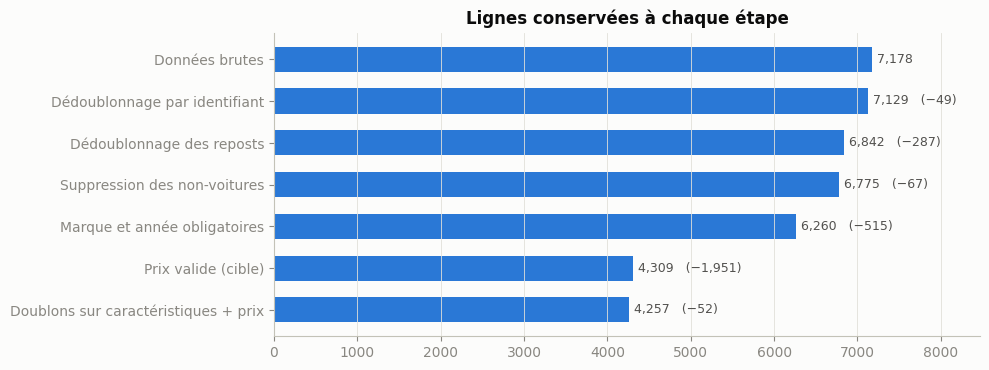

,étape,lignes,retirées
0,Données brutes,7178,0
1,Dédoublonnage par identifiant,7129,49
2,Dédoublonnage des reposts,6842,287
3,Suppression des non-voitures,6775,67
4,Marque et année obligatoires,6260,515
5,Prix valide (cible),4309,1951
6,Doublons sur caractéristiques + prix,4257,52


In [16]:
steps = pd.DataFrame(funnel, columns=["étape", "lignes"])
steps["retirées"] = (-steps["lignes"].diff()).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(steps["étape"], steps["lignes"], color=C1, height=0.6)
for y, (n, r) in enumerate(zip(steps["lignes"], steps["retirées"])):
    ax.text(n + 60, y, f"{n:,}" + (f"   (−{r:,})" if r else ""), va="center", color="#52514e", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, steps["lignes"].max() * 1.18)
ax.grid(axis="y", visible=False)
ax.set_title("Lignes conservées à chaque étape")
plt.tight_layout()
plt.show()
steps

## 12. Imputation dans le pipeline de modélisation

Les valeurs manquantes restantes ne peuvent être complétées qu'à partir d'autres annonces (par exemple, le kilométrage
médian des voitures de la même année). Ces statistiques doivent être **apprises sur le jeu d'entraînement uniquement**,
puis appliquées telles quelles au jeu de test et, plus tard, aux voitures saisies dans l'application. C'est la seule
façon d'obtenir une évaluation honnête et un comportement identique en production.

Elles sont implémentées dans `src/features.py` sous forme de transformers scikit-learn, à placer dans un `Pipeline` :

| Colonne | Imputation (apprise sur l'entraînement) |
|---|---|
| `kilometrage` | médiane par (année, état) → par année → globale |
| `cylindree` | médiane par (marque, modèle) → par puissance fiscale → globale |
| `puissance_fiscale` | médiane par (marque, modèle) → par cylindrée → globale |
| `boite` | valeur la plus fréquente par (marque, modèle, année) → (marque, modèle) → marque |
| autres catégories | valeur explicite `inconnu` |

Démonstration sur un découpage 80 / 20 (le découpage définitif est fait dans le notebook de modélisation) : les
statistiques sont apprises sur l'entraînement, puis toutes les valeurs manquantes du test sont complétées.

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from src.features import HierarchicalImputer, CategoricalFiller

imputer = make_pipeline(
    HierarchicalImputer("kilometrage", [["annee", "etat_du_vehicule"], ["annee"]], "median"),
    HierarchicalImputer("cylindree", [["marque", "modele"], ["puissance_fiscale"]], "median"),
    HierarchicalImputer("puissance_fiscale", [["marque", "modele"], ["cylindree"]], "median"),
    HierarchicalImputer("boite", [["marque", "modele", "annee"], ["marque", "modele"], ["marque"]], "mode"),
    CategoricalFiller(["modele", "carburant", "type_de_carrosserie", "couleur_du_vehicule", "etat_du_vehicule", "boite"]),
)

train, test = train_test_split(df, test_size=0.2, random_state=42)
imputer.fit(train[FEATURES])                      # statistiques apprises sur le train seulement
test_imputed = imputer.transform(test[FEATURES])  # appliquées au test sans les recalculer

pd.DataFrame({"NaN test avant": test[FEATURES].isna().sum(), "NaN test après": test_imputed.isna().sum()}).T

,kilometrage,annee,cylindree,puissance_fiscale,marque,modele,boite,carburant,type_de_carrosserie,couleur_du_vehicule,etat_du_vehicule
NaN test avant,45,0,65,96,0,30,14,15,84,10,46
NaN test après,0,0,0,0,0,0,0,0,0,0,0


## 13. Bilan et limites

**Résultat** : 4 257 annonces exploitables sur 7 178 collectées, avec un prix vérifié, et une trace de chaque
correction appliquée. 848 annonces ont été récupérées par correction (775 prix saisis en milliers, 35 en millimes,
38 prix retrouvés dans le texte) au lieu d'être supprimées, et le jeu de données ne contient plus de doublon, de puissance
fiscale aberrante, de kilométrage saisi en milliers ni de prix factice.

**Ce qui rend la démarche robuste**

- Corrections ciblées et justifiées plutôt que seuils arbitraires, chacune vérifiée par un contrôle de plausibilité.
- Règles de nettoyage isolées dans `src/cleaning.py`, réutilisables par l'application.
- Séparation stricte entre corrections ligne par ligne (ici) et imputations apprises (pipeline de modélisation) :
  aucune fuite d'information du test vers l'entraînement.

**Limites connues**

- Beaucoup de modèles sont rares (moins de 5 annonces) : leur traitement est étudié lors de la modélisation.
- Le contrôle de plausibilité dépend de la qualité des annonces de référence ; quelques annonces correctes sont rejetées.
- Certaines incohérences marque / modèle du site ne sont pas corrigées (ex. Kia Seltos saisi « Sephia »).
- La ville de l'annonce (57 % manquante) n'est pas exploitée : piste d'amélioration.

**Étape suivante** : `03_modeling.ipynb`, entraînement et évaluation des modèles sur `tayara_cars_cleaned.csv`.